# Análise de Desempenho Computacional e Viabilidade em Tempo Real

**Projeto:** Diagnóstico de Falhas em Rolamentos via CNN + Transformada Wavelet Contínua  
**Dataset de Referência:** Case Western Reserve University (CWRU – 4 classes, 7.100 treino / 2.364 val / 2.368 teste)  
**Hardware de Medição:** GPU NVIDIA GeForce RTX 2060 SUPER | CPU AMD Ryzen 5 2600 Six-Core Processor  
**Objetivo:** Executar e medir diretamente neste notebook todas as métricas de custo computacional das quatro arquiteturas avaliadas:
1. Quantidade total de parâmetros treináveis (M);
2. Complexidade matemática pura em GFLOPs (*Giga Floating-Point Operations*) por amostra;
3. Latência de inferência amostra a amostra (*batch size = 1*) em GPU e em CPU;
4. Tempo de pré-processamento (geração do escalograma CWT na CPU);
5. Ciclo total de diagnóstico (CWT + CNN na CPU) confrontado com a janela física de aquisição (85,33 ms);
6. Tempo médio de treinamento por época em GPU.

## 1. Configuração do Ambiente e Identificação de Hardware

Identificamos o dispositivo acelerador ativo (CUDA/GPU), processador do sistema e número de threads ativas para inferência.

In [5]:
import sys
import time
import platform
from pathlib import Path

# Configurar diretório raiz do projeto
BASE_DIR = Path.cwd().parent.parent if Path.cwd().name in ['1_cwru', '2_paderborn', '3_cross_domain', '4_order_tracking', '5_xjtu'] else Path.cwd().parent
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.flop_counter import FlopCounterMode

from src.config import FS, WINDOW_SIZE, BATCH_SIZE
from src.cnn_processor import BearingCNN
from src.transfer_learning import build_transfer_model
from src.cwt_processor import compute_cwt, scalogram_to_rgb
from src.benchmark_desempenho import (
    load_model, count_gflops, measure_latency, 
    measure_epoch_training_time, measure_cwt_time, 
    plot_performance_comparison, MODELS, NUM_CLASSES, WARMUP, RUNS_GPU, RUNS_CPU
)

# Fixar reprodutibilidade
torch.manual_seed(42)
np.random.seed(42)

has_gpu = torch.cuda.is_available()
gpu_name = torch.cuda.get_device_name(0) if has_gpu else 'N/A'
cpu_name = platform.processor()
window_ms = 1000.0 * WINDOW_SIZE / FS

print('=' * 85)
print(' AMBIENTE DE EXPERIMENTAÇÃO DE DESEMPENHO COMPUTACIONAL')
print('=' * 85)
print(f'GPU Ativa:             {gpu_name}')
print(f'CPU:                   {cpu_name}')
print(f'Threads PyTorch:       {torch.get_num_threads()}')
print(f'Versão do PyTorch:     {torch.__version__}')
print(f'Janela Física de Sinal: {WINDOW_SIZE} pontos a {FS} Hz = {window_ms:.2f} ms')
print('=' * 85)

 AMBIENTE DE EXPERIMENTAÇÃO DE DESEMPENHO COMPUTACIONAL
GPU Ativa:             NVIDIA GeForce RTX 2060 SUPER
CPU:                   AMD64 Family 23 Model 8 Stepping 2, AuthenticAMD
Threads PyTorch:       6
Versão do PyTorch:     2.5.1+cu121
Janela Física de Sinal: 1024 pontos a 12000 Hz = 85.33 ms


## 2. Medição do Tempo de Pré-Processamento (Transformada Wavelet Contínua na CPU)

Antes de qualquer classificação pela CNN, a janela temporal unidimensional (1.024 pontos) precisa ser convertida no escalograma bidimensional (224×224 RGB).  
A célula abaixo executa 50 transformadas consecutivas na CPU com a wavelet Morlet complexa (`cmor1.5-1.0`) e calcula o tempo médio e desvio padrão.

In [6]:
print('[+] Medindo tempo de cálculo da CWT na CPU (50 repetições)...')
cwt_times = measure_cwt_time()
cwt_mean_ms = float(cwt_times.mean())
cwt_std_ms = float(cwt_times.std())

print(f'-> Tempo CWT: {cwt_mean_ms:.2f} ± {cwt_std_ms:.2f} ms')
print(f'-> Fração da janela física ({window_ms:.2f} ms) consumida pela CWT: {(cwt_mean_ms / window_ms) * 100:.1f}%')

[+] Medindo tempo de cálculo da CWT na CPU (50 repetições)...
-> Tempo CWT: 64.06 ± 5.96 ms
-> Fração da janela física (85.33 ms) consumida pela CWT: 75.1%


## 3. Medição Direta das 4 Arquiteturas Neurais

Para cada um dos 4 modelos (`BearingCNN`, `ResNet-18`, `EfficientNet-B0`, `Inception-v3`):
1. Carregamos os pesos ótimos salvos pelo *checkpoint* no CWRU;
2. Contamos o número exato de parâmetros treináveis;
3. Calculamos os GFLOPs exatos da inferência via `torch.utils.flop_counter.FlopCounterMode`;
4. Cronometramos a latência de inferência na GPU (200 execuções com sincronização CUDA);
5. Cronometramos a latência de inferência na CPU (50 execuções);
6. Simulamos a duração média de uma época completa de treino (treino + validação).

In [7]:
rows = []
print('=' * 95)
print(f'{"Modelo":<18} | {"Parâm. (M)":>10} | {"GFLOPs":>8} | {"Treino/Época":>14} | {"GPU (ms)":>15} | {"CPU (ms)":>15}')
print('-' * 95)

for name, (key, ckpt, acc_cwru) in MODELS.items():
    # 1. Carregar modelo e pesos
    model, img_size = load_model(key, ckpt)
    
    # 2. Contagem de parâmetros
    params_m = sum(p.numel() for p in model.parameters()) / 1e6
    
    # 3. Contagem de GFLOPs
    gflops = count_gflops(model, img_size)
    
    # 4. Latência na CPU e GPU
    cpu_t = measure_latency(model, img_size, torch.device('cpu'), runs=RUNS_CPU)
    gpu_t = measure_latency(model, img_size, torch.device('cuda'), runs=RUNS_GPU) if has_gpu else np.array([np.nan])
    
    # 5. Tempo de treino por época
    epoch_s = measure_epoch_training_time(key, img_size, torch.device('cuda')) if has_gpu else np.nan
    
    total_cpu = cwt_mean_ms + cpu_t.mean()
    
    rows.append({
        'modelo': name,
        'parametros_M': params_m,
        'gflops': gflops,
        'treino_epoca_s': epoch_s,
        'treino_10ep_min': epoch_s * 10.0 / 60.0,
        'gpu_ms_media': float(gpu_t.mean()),
        'gpu_ms_desvio': float(gpu_t.std()),
        'cpu_ms_media': float(cpu_t.mean()),
        'cpu_ms_desvio': float(cpu_t.std()),
        'total_cpu_ms': total_cpu,
        'acuracia_cwru': acc_cwru
    })
    
    gpu_str = f'{gpu_t.mean():.2f} ± {gpu_t.std():.2f}'
    cpu_str = f'{cpu_t.mean():.2f} ± {cpu_t.std():.2f}'
    print(f'{name:<18} | {params_m:>9.2f}M | {gflops:>8.2f} | {epoch_s:>12.2f} s | {gpu_str:>15} | {cpu_str:>15}')
    
    del model
    if has_gpu:
        torch.cuda.empty_cache()

print('=' * 95)
df_bench = pd.DataFrame(rows)

Modelo             | Parâm. (M) |   GFLOPs |   Treino/Época |        GPU (ms) |        CPU (ms)
-----------------------------------------------------------------------------------------------
BearingCNN         |      0.52M |     1.47 |        11.18 s |     1.69 ± 0.16 |    19.60 ± 0.58
ResNet-18          |     11.18M |     3.63 |        14.00 s |     5.17 ± 0.45 |    43.25 ± 3.77
EfficientNet-B0    |      4.01M |     0.77 |        22.58 s |    17.01 ± 1.56 |    34.29 ± 1.85
Inception-v3       |     21.79M |    11.42 |        64.53 s |    24.61 ± 1.88 |   135.61 ± 6.86


## 4. Tabela Consolidada de Desempenho Computacional (Tabela do TCC)

Abaixo, formatamos os resultados calculados exatamente como apresentados na **Tabela do Capítulo de Resultados e Discussões** da monografia:

In [8]:
df_exibicao = pd.DataFrame({
    'Modelo': df_bench['modelo'],
    'Parâm. (M)': df_bench['parametros_M'].map(lambda v: f'{v:.2f} M'),
    'GFLOPs': df_bench['gflops'].map(lambda v: f'{v:.2f}'),
    'Treino/Época (GPU)': df_bench['treino_epoca_s'].map(lambda v: f'{v:.2f} s'),
    'Treino 10 Épocas': df_bench['treino_10ep_min'].map(lambda v: f'{v:.2f} min'),
    'Inferência GPU (ms)': [f'{m:.2f} ± {s:.2f}' for m, s in zip(df_bench['gpu_ms_media'], df_bench['gpu_ms_desvio'])],
    'Inferência CPU (ms)': [f'{m:.2f} ± {s:.2f}' for m, s in zip(df_bench['cpu_ms_media'], df_bench['cpu_ms_desvio'])],
    'Total CPU (CWT + CNN)': df_bench['total_cpu_ms'].map(lambda v: f'{v:.2f} ms'),
    'Tempo Real CPU?': df_bench['total_cpu_ms'].map(lambda v: 'Sim (Viável)' if v <= window_ms else 'Não (Gargalo)')
})

print('TABELA OFICIAL DO TCC: DESEMPENHO COMPUTACIONAL NO CWRU')
display(df_exibicao)

TABELA OFICIAL DO TCC: DESEMPENHO COMPUTACIONAL NO CWRU


,Modelo,Parâm. (M),GFLOPs,Treino/Época (GPU),Treino 10 Épocas,Inferência GPU (ms),Inferência CPU (ms),Total CPU (CWT + CNN),Tempo Real CPU?
0,BearingCNN,0.52 M,1.47,11.18 s,1.86 min,1.69 ± 0.16,19.60 ± 0.58,83.66 ms,Sim (Viável)
1,ResNet-18,11.18 M,3.63,14.00 s,2.33 min,5.17 ± 0.45,43.25 ± 3.77,107.31 ms,Não (Gargalo)
2,EfficientNet-B0,4.01 M,0.77,22.58 s,3.76 min,17.01 ± 1.56,34.29 ± 1.85,98.35 ms,Não (Gargalo)
3,Inception-v3,21.79 M,11.42,64.53 s,10.75 min,24.61 ± 1.88,135.61 ± 6.86,199.67 ms,Não (Gargalo)


## 5. Visualização Comparativa e Exportação das Figuras da Monografia

Geramos o painel comparativo triplo e o gráfico de *trade-off* (acurácia versus latência) e salvamos diretamente em `docs/images/`.

[INFO] Figura salva em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\desempenho_computacional_comparacao.png


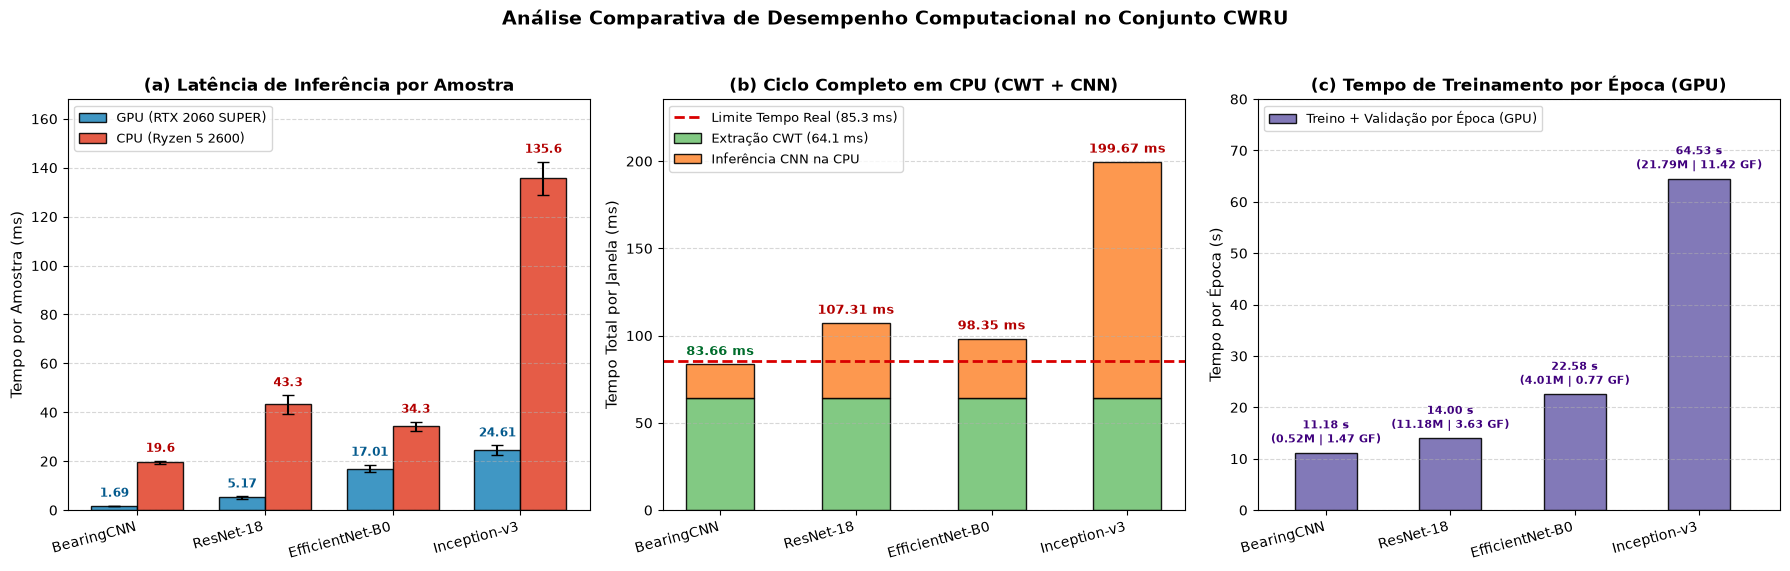

[INFO] Gráfico de trade-off salvo em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\desempenho_tradeoff_acuracia_latencia.png


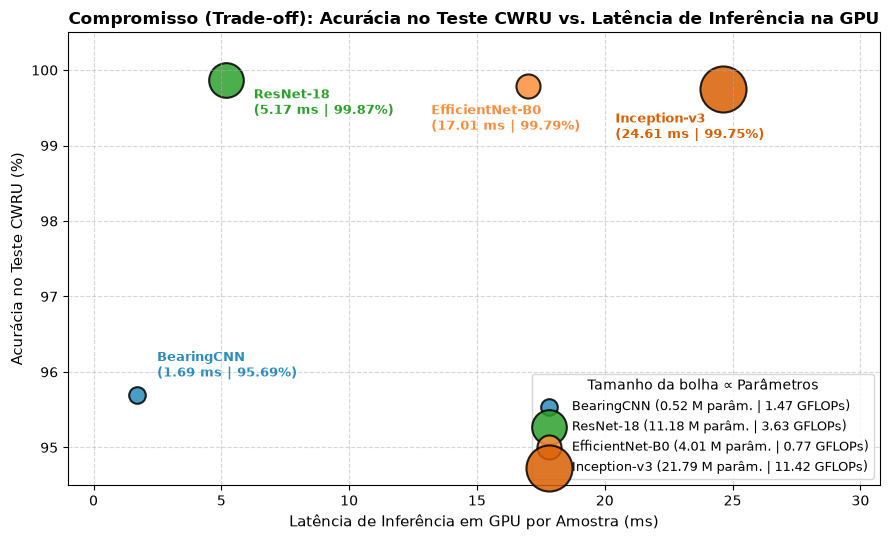

In [9]:
save_fig_1 = BASE_DIR / 'docs' / 'images' / 'desempenho_computacional_comparacao.png'
plot_performance_comparison(
    df=df_bench,
    cwt_ms=cwt_mean_ms,
    window_ms=window_ms,
    save_path=save_fig_1
)

# Gráfico 2: Trade-off Acurácia vs. Latência
fig, ax = plt.subplots(figsize=(9, 5.5))
cores = ['#2b8cbe', '#2ca02c', '#fd8d3c', '#d95f02']
offsets = [(0.8, 0.25), (1.1, -0.45), (-3.8, -0.58), (-4.2, -0.65)]

for i, row in df_bench.iterrows():
    tamanho_bolha = row['parametros_M'] * 45 + 120
    ax.scatter(row['gpu_ms_media'], row['acuracia_cwru'], s=tamanho_bolha,
               color=cores[i], alpha=0.85, edgecolors='black', linewidth=1.5,
               label=f"{row['modelo']} ({row['parametros_M']:.2f} M parâm. | {row['gflops']:.2f} GFLOPs)")
    dx, dy = offsets[i]
    ax.annotate(
        f"{row['modelo']}\n({row['gpu_ms_media']:.2f} ms | {row['acuracia_cwru']:.2f}%)",
        (row['gpu_ms_media'] + dx, row['acuracia_cwru'] + dy),
        fontsize=9, fontweight='bold', color=cores[i]
    )

ax.set_title('Compromisso (Trade-off): Acurácia no Teste CWRU vs. Latência de Inferência na GPU', fontsize=12, fontweight='bold')
ax.set_xlabel('Latência de Inferência em GPU por Amostra (ms)', fontsize=11)
ax.set_ylabel('Acurácia no Teste CWRU (%)', fontsize=11)
ax.set_ylim(94.5, 100.5)
ax.set_xlim(-1, max(df_bench['gpu_ms_media']) * 1.25)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(title='Tamanho da bolha ∝ Parâmetros', fontsize=9, loc='lower right')
plt.tight_layout()

save_fig_2 = BASE_DIR / 'docs' / 'images' / 'desempenho_tradeoff_acuracia_latencia.png'
plt.savefig(save_fig_2, dpi=300, bbox_inches='tight')
print(f'[INFO] Gráfico de trade-off salvo em: {save_fig_2}')
plt.show()

## 6. Persistência dos Resultados em CSV

Salvamos os dados medidos em `results/benchmark_desempenho.csv` para referência futura e auditoria.

In [10]:
results_dir = BASE_DIR / 'results'
results_dir.mkdir(parents=True, exist_ok=True)
out_csv = results_dir / 'benchmark_desempenho.csv'

header_comment = f'# cwt_ms_media={cwt_mean_ms:.2f},cwt_ms_desvio={cwt_std_ms:.2f},janela_ms={window_ms:.2f},gpu={gpu_name},cpu={cpu_name}\n'
csv_text = header_comment + df_bench.to_csv(index=False)
out_csv.write_text(csv_text, encoding='utf-8')
print(f'[INFO] Benchmark salvo com sucesso em: {out_csv}')

[INFO] Benchmark salvo com sucesso em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\results\benchmark_desempenho.csv
